In [1]:
import json
import collections

import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import PreTrainedTokenizerFast


stats = json.load(open('data/stats.json'))
examples = json.load(open('data/removed_examples.json'))
df = pd.read_parquet('data/clean.parquet')

/Users/leoqay/homework/text_processings/hw1/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Анализ корпуса и токенизатора

## 1. Источники

| источник | что это |  |
|---|---|---|
| FineWeb-2 chv_Cyrl | веб, уже отфильтрован по языку и дедуплицирован | самый большой и разнообразный (новости, литература, образование) |
| Wikipedia 20231101.cv | спарсили википедию | факты, чистый язык; много странных/пустых статей |
| Leipzig chv_community_2017 | готовые предложения (не документы) | |

Страницы FineWeb с cv.wikipedia.org выкидываю и в место них беру Wikipedia 20231101.cv

In [2]:
raw, clean = stats['raw'], stats['clean']

tab = pd.DataFrame({
    s: {
        'документов до': raw[f'{s}_docs'],
        'M символов до': raw[f'{s}_chars'] / 1e6,
        'документов после': clean[f'{s}_docs'],
        'M символов после': clean[f'{s}_chars'] / 1e6,
    }
    for s in ['fineweb2', 'wikipedia', 'leipzig']
}).T

tab['осталось %'] = 100 * tab['M символов после'] / tab['M символов до']

print('Выкинуто копий cv.wikipedia.org из FineWeb:', stats['fineweb_wiki_copies_dropped'])
print(
    f"Чистый корпус: {stats['clean_chars_total'] / 1e6:.0f}M символов, "
    f"{stats['clean_mb_utf8']} MB в UTF-8, {stats['words_total'] / 1e6:.1f}M слов"
)

tab.round(1)

Выкинуто копий cv.wikipedia.org из FineWeb: 6436
Чистый корпус: 201M символов, 366.7 MB в UTF-8, 26.7M слов


,документов до,M символов до,документов после,M символов после,осталось %
fineweb2,74944.0,222.0,67520.0,178.9,80.6
wikipedia,51863.0,42.3,31554.0,17.8,42.0
leipzig,2378.0,5.5,2373.0,4.7,85.4


## 2. Этапы очистки

1. **Нормализация.** Чувашском алфавит это: русский алфавит + 4 буквы (ӑ ӗ ҫ ӳ). Долгое время не было чувашской раскладки, поэтому вместо нее часто набирают похожие (ă ĕ ç ÿ). Добавил замены в нормализации текста.

2. **Отфильтровал строки, которые:**
- слишком короткие и без знака конца предложения
- латиница > 30% букв
- строки со ссылками и e-mail
- строки без букв (номера страниц, разделители)

3. **Языковой фильтр.**
- Главная примесь — русский (двуязычные сайты). Строка считается русской, если ≥ 8% ее слов — русские стоп-слова и чувашских маркеров меньше, чем русских.
- Чувашские маркеры — слова с ӑ ӗ ҫ ӳ и чувашские стоп-слова.

4. **Фильтр документов.**
- В чувашском тексте чувашские буквы — это ~5% всех букв.
- Если их < 1%, документ либо не чувашский (русский), либо набран в сломанной кодировке. Такие выкидываю.

5. **Дедупликация.**

Заменено двойников: 19,646,482


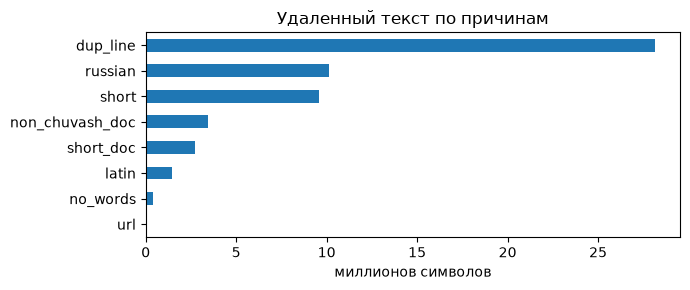

In [3]:
print(f"Заменено двойников: {stats['lookalike_chars']:,}")

removed = pd.Series(stats['removed_chars']).sort_values() / 1e6

ax = removed.plot.barh(figsize=(7, 3), title='Удаленный текст по причинам')
ax.set_xlabel('миллионов символов')

plt.tight_layout()

In [4]:
for reason in ['russian', 'non_chuvash_doc', 'dup_line', 'short', 'latin']:
    print(f'== {reason}')

    for x in examples[reason][:4]:
        print('   ', x[:150].replace('\n', ' '))

== russian
    -Пуйас хускалса кайре, пурте лавесленче рна-и?
    Сценарий праздника "Прощание с 1 книгой Азбукой " на чувашском языке. Разработка очень интересна и проста для проведения праздника. Сценарий расчитан 
    |Включите уведомления прямо сейчас и мы сразу сообщим Вам о важных новостях. Не волнуйтесь, мы будем отправлять только самое главное.|
    (конкурс сразу по 24 предметам за один оргвзнос)
== non_chuvash_doc
    Тема: Сыва пул, перремеш кенекемер! Теллевесем: 1. Веренне сас паллисене аса илсе сиреплетесси. 2. Ачасен тавсарулахне, сыханулла каласуне аталантарас
    А. С . ПУШКИН Ь Гуоц •4 КНИГОХРАНИЛИЩЕ ЦЛУ. ЧАССР. Иивент. КИР Д Ж А Л И Вырасларан В. Хударсем кусарна ЧАВАШ АССР ГОСУДАРСТВО ИЗДАТЕЛЬСТВИ Ш У П А Ш 
    Презентация на тему: " Тёван Ен культури +.ршывём=ём: Чёваш =.ршыв. Кирек ё=та пулсассён та Ман асёмра эс ч.р.: сывё: Пуласч. хам та асунта Ин=ет =.рш
    Ака уйaхeн 17-мeшeнче шупашкарти Г.С. Лебедев ячeллe лицейра «Cамрaк чaваш cыравcисен И.Я. Яковлева хал

## 3. Статистика корпуса

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
fineweb2,67520.0,2649.0,5915.0,200.0,819.0,1634.0,3090.0,556169.0
leipzig,2373.0,1994.0,434.0,276.0,1749.0,2000.0,2270.0,3500.0
wikipedia,31554.0,563.0,941.0,200.0,251.0,286.0,530.0,45774.0


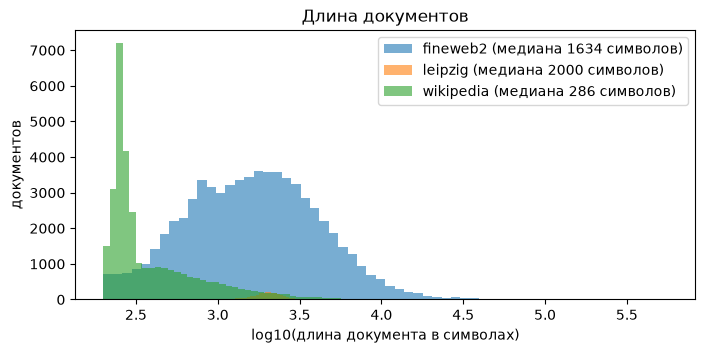

In [5]:
df['chars'] = df.text.str.len()

fig, ax = plt.subplots(figsize=(8, 3.5))

for s, g in df.groupby('source'):
    ax.hist(np.log10(g.chars), bins=60, alpha=.6, label=f'{s} (медиана {int(g.chars.median())} символов)')

ax.set_xlabel('log10(длина документа в символах)')
ax.set_ylabel('документов')
ax.legend()
ax.set_title('Длина документов')

df.groupby('source').chars.describe().round(0)

### Частоты слов

In [6]:
words = pd.read_csv('data/word_counts.tsv', sep='\t', keep_default_na=False)
total = words['count'].sum()

print(f'Всего слов в тексте: {total:,}')
print(f'Разных слов: {len(words):,}')
print(f'Встречаются всего один раз: {stats["hapax_share_of_vocab"]:.1%} различных слов')

words.head(15)

Всего слов в тексте: 26,698,694
Разных слов: 647,082
Встречаются всего один раз: 47.4% различных слов


,word,count
0,те,398471
1,та,279890
2,тата,214066
3,вӑл,184563
4,чӑваш,148803
5,пӗр,113647
6,мар,101385
7,ӑна,91338
8,ҫул,91280
9,ҫак,87547


### Закон Ципфа

У нас закон хорошо выполняется в середине (ранги 100–10000, наклон ≈ −1). Самые частые слова (те, та, тата) встречаются реже, чем предсказывает закон, а хвост падает круче: редкие словоформы встречаются еще реже, чем 1/r.

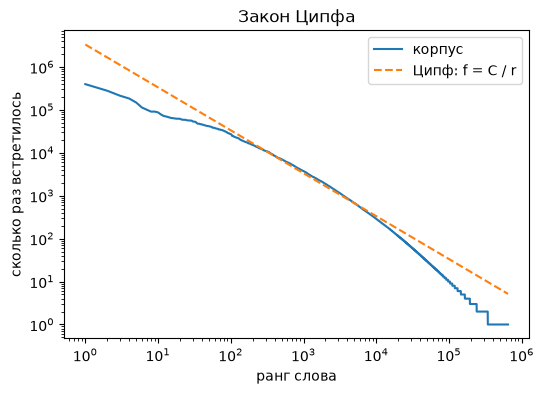

In [7]:
rank = np.arange(1, len(words) + 1)
C = (words['count'] * rank)[100:10000].median()

plt.figure(figsize=(6, 4))
plt.loglog(rank, words['count'], label='корпус')
plt.loglog(rank, C / rank, '--', label='Ципф: f = C / r')
plt.xlabel('ранг слова')
plt.ylabel('сколько раз встретилось')
plt.title('Закон Ципфа')
plt.legend()

### Покрытие

Какую долю всего текста составляют k самых частых слов.
- немного частых слов дают большую часть текста
- но хвост из редких слов огромный: чтобы покрыть 95% текста, нужно ~100 тыс. словоформ

топ-100 слов: 20.8% текста
топ-1000 слов: 48.9% текста
топ-10000 слов: 79.2% текста
топ-100000 слов: 95.5% текста


Text(0.5, 1.0, 'Покрытие')

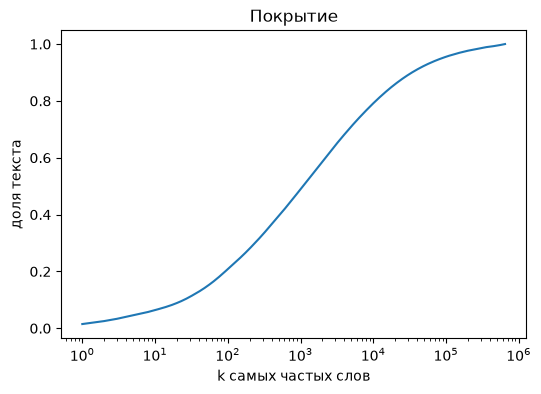

In [8]:
cover = words['count'].cumsum() / total

for k in [100, 1000, 10000, 100000]:
    print(f'топ-{k} слов: {cover.iloc[k - 1]:.1%} текста')

plt.figure(figsize=(6, 4))
plt.semilogx(rank, cover)
plt.xlabel('k самых частых слов')
plt.ylabel('доля текста')
plt.title('Покрытие')


- разных словоформ очень много: ~650 тыс., половина встречается один раз.
- нужен subword-токенизатор: слово делится на основу и суффиксы.

In [9]:
chv = collections.Counter(c for t in df.text.sample(3000, random_state=0) for c in t if c in 'ӑӗҫӳӐӖҪӲăĕçÿ')

{c: (unicodedata.name(c), n) for c, n in chv.most_common()}

{'ӑ': ('CYRILLIC SMALL LETTER A WITH BREVE', 255604),
 'ӗ': ('CYRILLIC SMALL LETTER IE WITH BREVE', 252575),
 'ҫ': ('CYRILLIC SMALL LETTER ES WITH DESCENDER', 139713),
 'ӳ': ('CYRILLIC SMALL LETTER U WITH DOUBLE ACUTE', 14639),
 'Ҫ': ('CYRILLIC CAPITAL LETTER ES WITH DESCENDER', 9761),
 'Ӑ': ('CYRILLIC CAPITAL LETTER A WITH BREVE', 1335),
 'Ӗ': ('CYRILLIC CAPITAL LETTER IE WITH BREVE', 1104),
 'Ӳ': ('CYRILLIC CAPITAL LETTER U WITH DOUBLE ACUTE', 163)}

## 4. Токенизатор

Byte-level BPE из HF tokenizers, как в GPT-2

Обучил на train со словарем 8k / 16k / 32k, метрики считаю на валидации.

In [10]:
metrics = json.load(open('tokenizers/metrics.json'))

tm = pd.DataFrame(metrics).T.drop(columns='sample')
emb = tm.embedding_params_d512
tm['доля эмбеддингов в small модели, %'] = (100 * emb / (emb + 25.7e6)).astype(float).round(1)

tm

,train_tokens,val_tokens,chars_per_token,tokens_per_word,unused_tokens_pct,rare_tokens_lt10_pct,rare_tokens_lt100_pct,embedding_params_d512,"доля эмбеддингов в small модели, %"
8000,52227445,260090,3.89,1.908,0.69,0.8,1.36,4096000,13.7
16000,46522503,231168,4.378,1.695,0.36,0.54,1.88,8192000,24.2
32000,42524176,211303,4.79,1.549,0.28,0.63,3.78,16384000,38.9


In [11]:
sample = 'Чӑваш Республикин тӗп хули — Шупашкар. Вӑл Атӑл юханшывӗн сылтӑм ҫыранӗнче вырнаҫнӑ.'

for v in metrics:
    tokenizer = PreTrainedTokenizerFast.from_pretrained(f'tokenizers/bpe{v}')

    print(f'{v:>6}:', ' | '.join(tokenizer.decode([i]) for i in tokenizer(sample).input_ids))

  8000: Чӑваш |  Республикин |  тӗп |  хули |  — |  Шупашкар | . |  Вӑл |  Атӑл |  юханшыв | ӗн |  сылтӑм |  ҫыран | ӗнче |  вырнаҫнӑ | .
 16000: Чӑваш |  Республикин |  тӗп |  хули |  — |  Шупашкар | . |  Вӑл |  Атӑл |  юханшыв | ӗн |  сылтӑм |  ҫыранӗнче |  вырнаҫнӑ | .
 32000: Чӑваш |  Республикин |  тӗп |  хули |  — |  Шупашкар | . |  Вӑл |  Атӑл |  юханшывӗн |  сылтӑм |  ҫыранӗнче |  вырнаҫнӑ | .


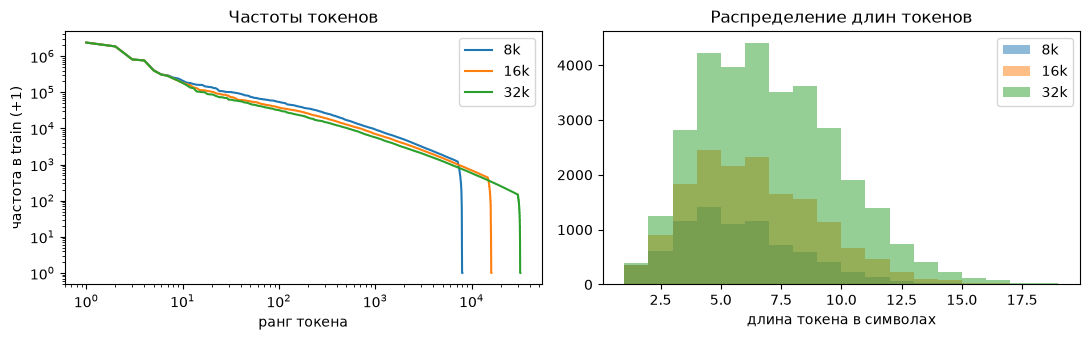

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

for v in metrics:
    counts = np.sort(np.load(f'data/tok{v}/token_counts.npy'))[::-1]
    ax[0].loglog(np.arange(1, len(counts) + 1), counts + 1, label=f'{int(v) // 1000}k')

    tokenizer = PreTrainedTokenizerFast.from_pretrained(f'tokenizers/bpe{v}')
    lens = [len(tokenizer.decode([i])) for i in range(len(tokenizer))]
    ax[1].hist(lens, bins=range(1, 20), alpha=.5, label=f'{int(v) // 1000}k')

ax[0].set_xlabel('ранг токена')
ax[0].set_ylabel('частота в train (+1)')
ax[0].legend()
ax[0].set_title('Частоты токенов')

ax[1].set_xlabel('длина токена в символах')
ax[1].legend()
ax[1].set_title('Распределение длин токенов')

plt.tight_layout()

In [13]:
for v in metrics:
    tokenizer = PreTrainedTokenizerFast.from_pretrained(f'tokenizers/bpe{v}')
    counts = np.load(f'data/tok{v}/token_counts.npy')

    rare = [i for i in np.argsort(counts) if counts[i] > 0][:12]
    unused = np.where(counts == 0)[0]

    print(f'{v}: самые редкие из использованных:', [(tokenizer.decode([i]), int(counts[i])) for i in rare])
    print(f'{v}: ни разу не встретились в train:', len(unused), [tokenizer.convert_ids_to_tokens(int(i)) for i in unused[:8]])

8000: самые редкие из использованных: [('�', 3), ('�', 3), ('лчӗк', 4), ('аҫҫей', 6), ('�', 7), ('ӗмӗшле', 7), ('хаил', 8), (' доку', 9), ('�', 9), ('�', 10), ('ПГӐ', 12), ('�', 13)]
8000: ни разу не встретились в train: 55 ['<|endoftext|>', '<pad>', 'À', 'Á', 'Ý', 'Þ', 'ß', 'î']
16000: самые редкие из использованных: [('аштав', 1), ('юдмила', 1), ('ашней', 1), (' инстру', 2), ('лтӑн', 2), ('емпля', 3), ('�', 3), ('�', 3), ('тепан', 4), ('лчӗк', 4), ('гнать', 4), (' Григорь', 5)]
16000: ни разу не встретились в train: 58 ['<|endoftext|>', '<pad>', 'À', 'Á', 'Ý', 'Þ', 'ß', 'î']
32000: самые редкие из использованных: [('ашней', 1), ('Григорь', 1), ('ӗрарӑм', 1), ('тудент', 1), (' лотер', 1), ('юдмила', 1), ('ктябрӗн', 1), (' соору', 1), ('ячеслав', 1), ('антина', 1), ('едак', 1), ('ample', 1)]
32000: ни разу не встретились в train: 90 ['<|endoftext|>', '<pad>', 'À', 'Á', 'Ý', 'Þ', 'ß', 'î']


**Выбрал 16k**
- 8k → 16k: последовательности короче на 11%
- 16k → 32k: короче еще только на 9%, но эмбеддингов вдвое больше (16.4M против 8.2M; в small это было бы почти 40% параметров)
- 8k против 16k проверил на трейне: модель tiny на 16k лучше по bits per character